In [ ]:
# 1. Package Installations
!pip install -q "keras==3.15.1"
!pip install -q gradio

In [ ]:
# 2. System and Machine Learning Imports
import os
import random
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
from PIL import Image
from collections import Counter

import tensorflow as tf
from tensorflow.keras import layers, models
import keras
import keras_hub

# Verify Versions and GPU Availability
print("TensorFlow version:", tf.__version__)
print("Keras version:", keras.__version__)
print("KerasHub version:", keras_hub.__version__)
print("GPU available:", tf.config.list_physical_devices('GPU'))

In [ ]:
# 3. Google Drive Mounting
from google.colab import drive
drive.mount('/content/drive')

In [ ]:
# 4. Global Configurations and Paths
BASE_PATH = "/content/drive/MyDrive/Honours_MP/Brain_Tumor_MRI"
TRAIN_PATH = os.path.join(BASE_PATH, "Training")
TEST_PATH = os.path.join(BASE_PATH, "Testing")

IMG_SIZE = (224, 224)
BATCH_SIZE = 32
SEED = 42

print("Training path:", TRAIN_PATH)
print("Testing path:", TEST_PATH)
print("Image size:", IMG_SIZE)
print("Batch size:", BATCH_SIZE)

In [ ]:
train_classes = sorted(os.listdir(TRAIN_PATH))
test_classes = sorted(os.listdir(TEST_PATH))

print("Training classes:")
for cls in train_classes:
    print(" -", cls)

print("\nTesting classes:")
for cls in test_classes:
    print(" -", cls)

Training classes:
 - glioma
 - meningioma
 - notumor
 - pituitary

Testing classes:
 - glioma
 - meningioma
 - notumor
 - pituitary


In [ ]:
from collections import Counter

def count_images(folder_path):
    counts = {}

    for class_name in sorted(os.listdir(folder_path)):
        class_path = os.path.join(folder_path, class_name)

        if os.path.isdir(class_path):
            image_files = [
                f for f in os.listdir(class_path)
                if f.lower().endswith(('.jpg', '.jpeg', '.png'))
            ]

            counts[class_name] = len(image_files)

    return counts


train_counts = count_images(TRAIN_PATH)
test_counts = count_images(TEST_PATH)

print("Training images:")
for cls, count in train_counts.items():
    print(f"{cls}: {count}")

print("\nTesting images:")
for cls, count in test_counts.items():
    print(f"{cls}: {count}")

print("\nTotal training images:", sum(train_counts.values()))
print("Total testing images:", sum(test_counts.values()))
print("Total images:", sum(train_counts.values()) + sum(test_counts.values()))

Training images:
glioma: 1400
meningioma: 1400
notumor: 1400
pituitary: 1400

Testing images:
glioma: 400
meningioma: 400
notumor: 400
pituitary: 400

Total training images: 5600
Total testing images: 1600
Total images: 7200


=== Class Distribution ===
Class              Train     Test
---------------------------------
glioma              1400      400
meningioma          1400      400
notumor             1400      400
pituitary           1400      400
TOTAL               5600     1600


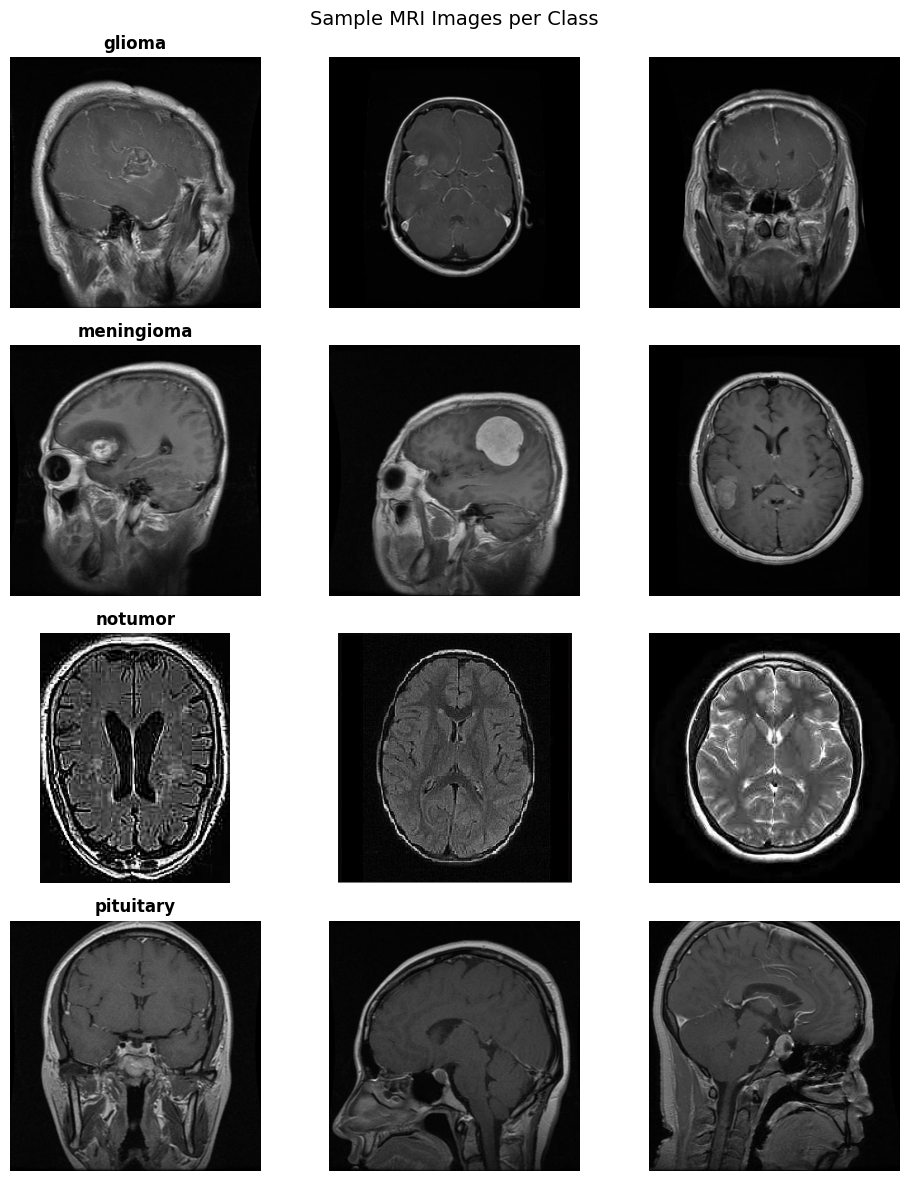

In [ ]:
import os
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
import random

# Class distribution
print("=== Class Distribution ===")
train_counts = {}
test_counts = {}

for cls in sorted(os.listdir(TRAIN_PATH)):
    cls_path = os.path.join(TRAIN_PATH, cls)
    if os.path.isdir(cls_path):
        train_counts[cls] = len(os.listdir(cls_path))

for cls in sorted(os.listdir(TEST_PATH)):
    cls_path = os.path.join(TEST_PATH, cls)
    if os.path.isdir(cls_path):
        test_counts[cls] = len(os.listdir(cls_path))

print(f"{'Class':<15} {'Train':>8} {'Test':>8}")
print("-" * 33)
for cls in train_counts:
    print(f"{cls:<15} {train_counts[cls]:>8} {test_counts.get(cls, 0):>8}")
print(f"{'TOTAL':<15} {sum(train_counts.values()):>8} {sum(test_counts.values()):>8}")

# Sample images — 3 per class
CLASSES = sorted(train_counts.keys())
fig, axes = plt.subplots(len(CLASSES), 3, figsize=(10, 12))
for i, cls in enumerate(CLASSES):
    cls_path = os.path.join(TRAIN_PATH, cls)
    samples = random.sample(os.listdir(cls_path), 3)
    for j, fname in enumerate(samples):
        img = mpimg.imread(os.path.join(cls_path, fname))
        axes[i][j].imshow(img, cmap='gray' if img.ndim == 2 else None)
        axes[i][j].axis('off')
        if j == 0:
            axes[i][j].set_title(cls, fontsize=12, fontweight='bold')
plt.suptitle("Sample MRI Images per Class", fontsize=14)
plt.tight_layout()
plt.savefig(os.path.join(BASE_PATH, "sample_images.png"), dpi=150)
plt.show()

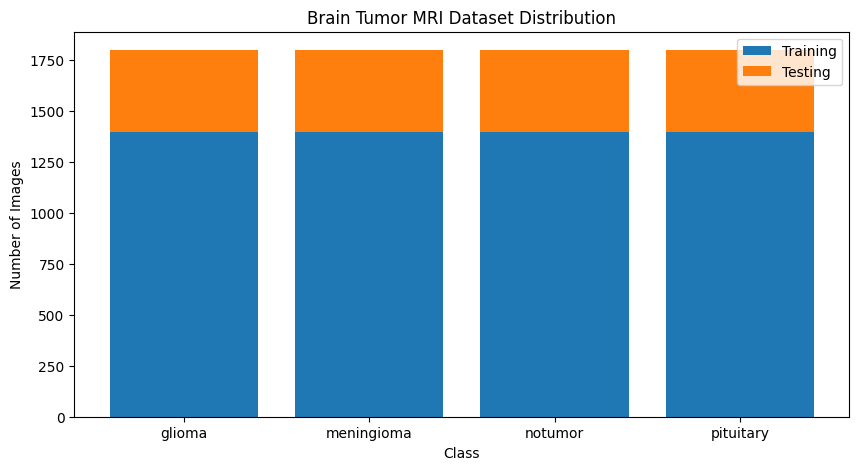

In [ ]:
import matplotlib.pyplot as plt

classes = list(train_counts.keys())
train_values = list(train_counts.values())
test_values = list(test_counts.values())

x = range(len(classes))

plt.figure(figsize=(10, 5))

plt.bar(x, train_values, label="Training")
plt.bar(x, test_values, bottom=train_values, label="Testing")

plt.xticks(x, classes)
plt.ylabel("Number of Images")
plt.xlabel("Class")
plt.title("Brain Tumor MRI Dataset Distribution")
plt.legend()

plt.show()

In [ ]:
from PIL import Image
import random

def get_image_dimensions(folder_path, samples_per_class=20):
    dimensions = []

    for class_name in os.listdir(folder_path):
        class_path = os.path.join(folder_path, class_name)

        if not os.path.isdir(class_path):
            continue

        image_files = [
            f for f in os.listdir(class_path)
            if f.lower().endswith(('.jpg', '.jpeg', '.png'))
        ]

        selected_files = random.sample(
            image_files,
            min(samples_per_class, len(image_files))
        )

        for file in selected_files:
            image_path = os.path.join(class_path, file)

            try:
                with Image.open(image_path) as img:
                    dimensions.append((img.size, img.mode))
            except:
                pass

    return dimensions


dimensions = get_image_dimensions(TRAIN_PATH)

print("Number of sampled images:", len(dimensions))
print("\nFirst 20 samples:")

for dimension, mode in dimensions[:20]:
    print("Size:", dimension, "| Mode:", mode)

Number of sampled images: 80

First 20 samples:
Size: (225, 225) | Mode: RGB
Size: (196, 257) | Mode: RGB
Size: (439, 512) | Mode: RGB
Size: (428, 417) | Mode: RGB
Size: (225, 225) | Mode: RGB
Size: (225, 225) | Mode: RGB
Size: (853, 480) | Mode: RGB
Size: (201, 251) | Mode: RGB
Size: (356, 474) | Mode: RGB
Size: (194, 259) | Mode: RGB
Size: (400, 442) | Mode: RGB
Size: (225, 225) | Mode: RGB
Size: (208, 242) | Mode: RGB
Size: (630, 630) | Mode: RGB
Size: (227, 262) | Mode: RGB
Size: (230, 235) | Mode: RGB
Size: (236, 260) | Mode: RGB
Size: (442, 442) | Mode: RGB
Size: (226, 213) | Mode: RGB
Size: (225, 225) | Mode: RGB


In [ ]:
from collections import Counter

mode_counts = Counter(mode for _, mode in dimensions)

print("Image color modes:")
for mode, count in mode_counts.items():
    print(f"{mode}: {count}")

Image color modes:
RGB: 47
L: 33


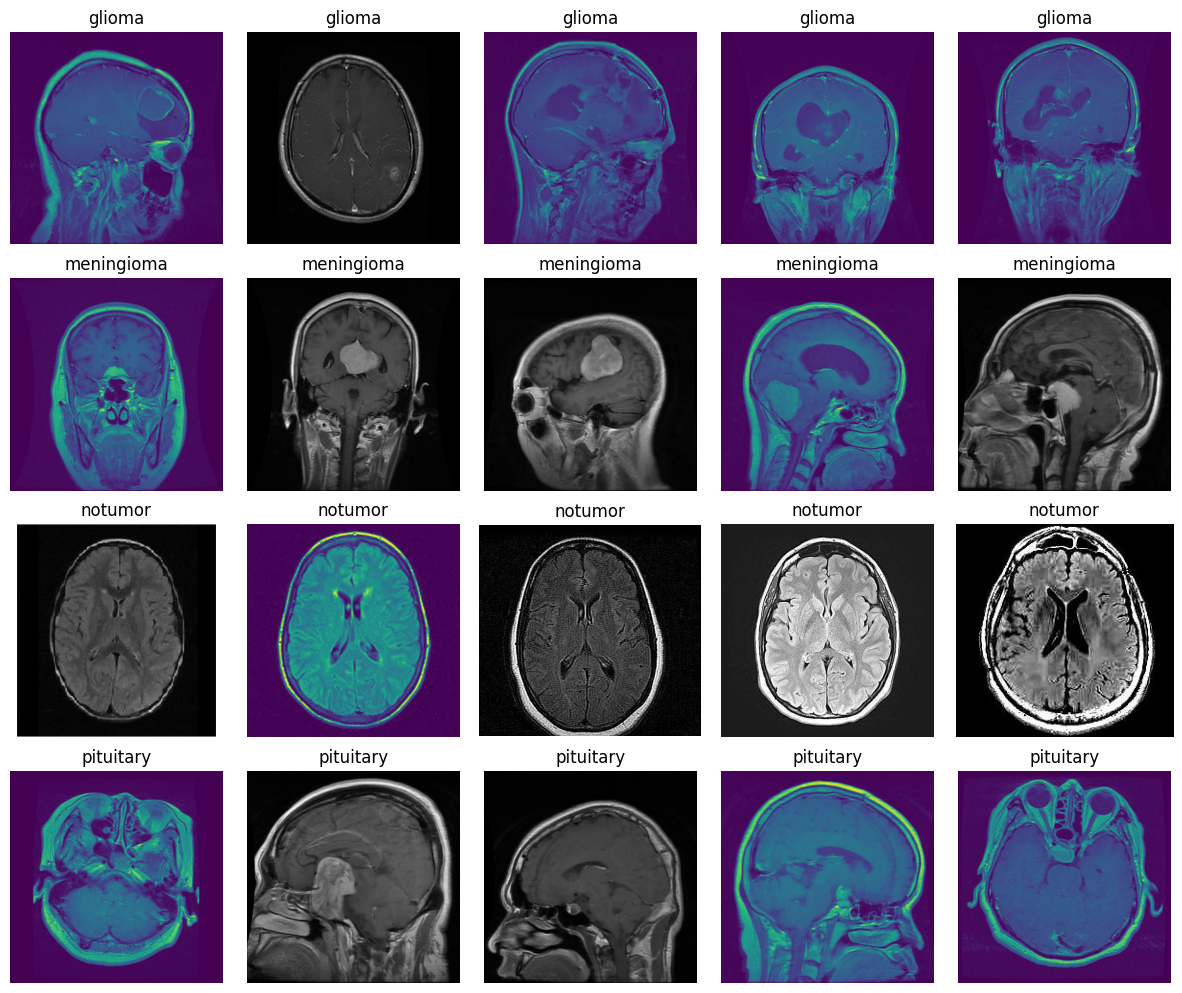

In [ ]:
plt.figure(figsize=(12, 10))

for i, class_name in enumerate(train_classes):

    class_path = os.path.join(TRAIN_PATH, class_name)

    image_files = [
        f for f in os.listdir(class_path)
        if f.lower().endswith(('.jpg', '.jpeg', '.png'))
    ]

    selected_files = random.sample(
        image_files,
        min(5, len(image_files))
    )

    for j, image_file in enumerate(selected_files):

        image_path = os.path.join(class_path, image_file)
        image = Image.open(image_path)

        position = i * 5 + j + 1

        plt.subplot(4, 5, position)
        plt.imshow(image)
        plt.title(class_name)
        plt.axis("off")

plt.tight_layout()
plt.show()

In [ ]:
import os

BASE_PATH = "/content/drive/MyDrive/Honours_MP/Brain_Tumor_MRI"

TRAIN_PATH = os.path.join(BASE_PATH, "Training")
TEST_PATH = os.path.join(BASE_PATH, "Testing")

print("Training path:", TRAIN_PATH)
print("Testing path:", TEST_PATH)

print("\nTraining folders:", os.listdir(TRAIN_PATH))
print("Testing folders:", os.listdir(TEST_PATH))

Training path: /content/drive/MyDrive/Honours_MP/Brain_Tumor_MRI/Training
Testing path: /content/drive/MyDrive/Honours_MP/Brain_Tumor_MRI/Testing

Training folders: ['notumor', 'pituitary', 'glioma', 'meningioma']
Testing folders: ['pituitary', 'meningioma', 'notumor', 'glioma']


In [ ]:
IMG_SIZE = (224, 224)
BATCH_SIZE = 32
SEED = 42

print("Image size:", IMG_SIZE)
print("Batch size:", BATCH_SIZE)

Image size: (224, 224)
Batch size: 32


In [ ]:
train_ds = tf.keras.utils.image_dataset_from_directory(
    TRAIN_PATH,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    color_mode="rgb",
    shuffle=True,
    seed=SEED
)

Found 5600 files belonging to 4 classes.


In [ ]:
val_ds = tf.keras.utils.image_dataset_from_directory(
    TEST_PATH,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    color_mode="rgb",
    shuffle=False
)

Found 1600 files belonging to 4 classes.


In [ ]:
class_names = train_ds.class_names

print("Class mapping:")

for i, class_name in enumerate(class_names):
    print(f"{i} → {class_name}")

Class mapping:
0 → glioma
1 → meningioma
2 → notumor
3 → pituitary


In [ ]:
for images, labels in train_ds.take(1):
    print("Image batch shape:", images.shape)
    print("Label batch shape:", labels.shape)
    print("Image data type:", images.dtype)

Image batch shape: (32, 224, 224, 3)
Label batch shape: (32,)
Image data type: <dtype: 'float32'>


In [ ]:
print("Training batches:",
      tf.data.experimental.cardinality(train_ds).numpy())

print("Validation batches:",
      tf.data.experimental.cardinality(val_ds).numpy())

Training batches: 175
Validation batches: 50


In [ ]:
AUTOTUNE = tf.data.AUTOTUNE

train_ds = train_ds.prefetch(buffer_size=AUTOTUNE)
val_ds = val_ds.prefetch(buffer_size=AUTOTUNE)

print("Dataset pipeline ready.")

Dataset pipeline ready.


In [ ]:
from tensorflow.keras import layers

data_augmentation = tf.keras.Sequential([
    layers.RandomRotation(0.05),
    layers.RandomZoom(0.10),
    layers.RandomTranslation(
        height_factor=0.05,
        width_factor=0.05
    ),
    layers.RandomContrast(0.10)
], name="data_augmentation")

print("Data augmentation pipeline created.")

Data augmentation pipeline created.


In [ ]:
normalization = layers.Rescaling(1./255)

print("Normalization layer created.")

Normalization layer created.


In [ ]:
for images, labels in train_ds.take(1):

    print("Original shape:", images.shape)
    print("Original minimum pixel value:", tf.reduce_min(images).numpy())
    print("Original maximum pixel value:", tf.reduce_max(images).numpy())

    augmented_images = data_augmentation(images)
    normalized_images = normalization(augmented_images)

    print("\nAfter augmentation:")
    print("Shape:", augmented_images.shape)

    print("\nAfter normalization:")
    print("Shape:", normalized_images.shape)
    print("Minimum pixel value:", tf.reduce_min(normalized_images).numpy())
    print("Maximum pixel value:", tf.reduce_max(normalized_images).numpy())

Original shape: (32, 224, 224, 3)
Original minimum pixel value: 0.0
Original maximum pixel value: 255.0

After augmentation:
Shape: (32, 224, 224, 3)

After normalization:
Shape: (32, 224, 224, 3)
Minimum pixel value: 0.0
Maximum pixel value: 1.0


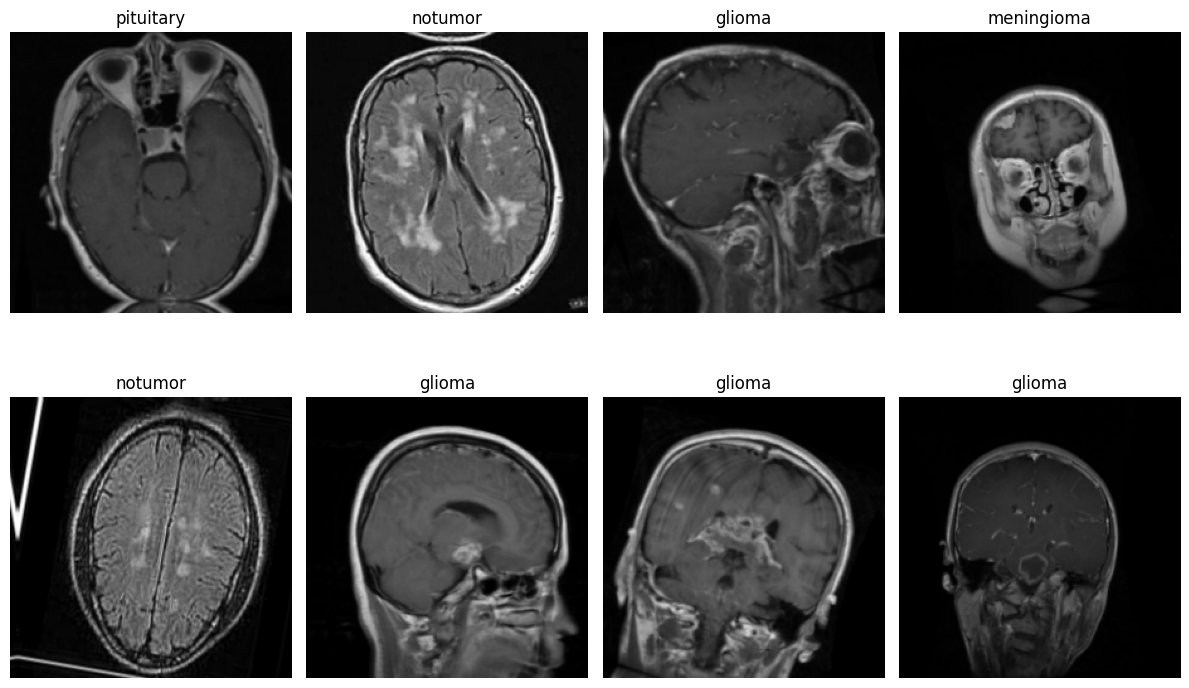

In [ ]:
import matplotlib.pyplot as plt

for images, labels in train_ds.take(1):

    plt.figure(figsize=(12, 8))

    for i in range(8):

        augmented_image = data_augmentation(images[i:i+1])
        augmented_image = augmented_image[0]

        plt.subplot(2, 4, i + 1)
        plt.imshow(
            augmented_image.numpy().astype("uint8")
        )
        plt.title(class_names[labels[i].numpy()])
        plt.axis("off")

    plt.tight_layout()
    plt.show()

In [ ]:
from tensorflow.keras import models, layers
cnn_model = models.Sequential([

    # Input
    layers.Input(shape=(224, 224, 3)),

    # Data augmentation
    data_augmentation,

    # Normalize pixels from 0-255 to 0-1
    layers.Rescaling(1./255),

    # Block 1
    layers.Conv2D(32, (3, 3), activation='relu', padding='same'),
    layers.MaxPooling2D((2, 2)),

    # Block 2
    layers.Conv2D(64, (3, 3), activation='relu', padding='same'),
    layers.MaxPooling2D((2, 2)),

    # Block 3
    layers.Conv2D(128, (3, 3), activation='relu', padding='same'),
    layers.MaxPooling2D((2, 2)),

    # Block 4
    layers.Conv2D(256, (3, 3), activation='relu', padding='same'),
    layers.MaxPooling2D((2, 2)),

    # Classification layers
    layers.Flatten(),

    layers.Dense(256, activation='relu'),
    layers.Dropout(0.5),

    layers.Dense(128, activation='relu'),
    layers.Dropout(0.3),

    # 4 classes
    layers.Dense(4, activation='softmax')
])

cnn_model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ data_augmentation (Sequential)  │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling_1 (Rescaling)         │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 224, 224, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 112, 112, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 112, 112, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 56, 56, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 56, 56, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 28, 28, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 28, 28, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 14, 14, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 50176)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │    12,845,312 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 4)              │           516 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 13,267,140 (50.61 MB)

 Trainable params: 13,267,140 (50.61 MB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
cnn_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.0001),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

print("CNN model compiled successfully.")

CNN model compiled successfully.


In [ ]:
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint

checkpoint_path = "/content/drive/MyDrive/Honours_MP/brain_tumor_cnn_best.keras"

early_stopping = EarlyStopping(
    monitor='val_loss',
    patience=5,
    restore_best_weights=True,
    verbose=1
)

model_checkpoint = ModelCheckpoint(
    checkpoint_path,
    monitor='val_loss',
    save_best_only=True,
    verbose=1
)

In [ ]:
EPOCHS = 20

history = cnn_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS,
    callbacks=[
        early_stopping,
        model_checkpoint
    ]
)

Epoch 1/20
175/175 ━━━━━━━━━━━━━━━━━━━━ 0s 8s/step - accuracy: 0.4144 - loss: 1.2494
Epoch 1: val_loss improved from None to 0.96105, saving model to /content/drive/MyDrive/Honours_MP/brain_tumor_cnn_best.keras

Epoch 1: finished saving model to /content/drive/MyDrive/Honours_MP/brain_tumor_cnn_best.keras
175/175 ━━━━━━━━━━━━━━━━━━━━ 1889s 11s/step - accuracy: 0.4964 - loss: 1.1199 - val_accuracy: 0.6494 - val_loss: 0.9610
Epoch 2/20
175/175 ━━━━━━━━━━━━━━━━━━━━ 0s 87ms/step - accuracy: 0.6213 - loss: 0.9036
Epoch 2: val_loss did not improve from 0.96105
175/175 ━━━━━━━━━━━━━━━━━━━━ 21s 117ms/step - accuracy: 0.6457 - loss: 0.8502 - val_accuracy: 0.6594 - val_loss: 1.0737
Epoch 3/20
175/175 ━━━━━━━━━━━━━━━━━━━━ 0s 86ms/step - accuracy: 0.6861 - loss: 0.7508
Epoch 3: val_loss improved from 0.96105 to 0.93178, saving model to /content/drive/MyDrive/Honours_MP/brain_tumor_cnn_best.keras

Epoch 3: finished saving model to /content/drive/MyDrive/Honours_MP/brain_tumor_cnn_best.keras
175/175

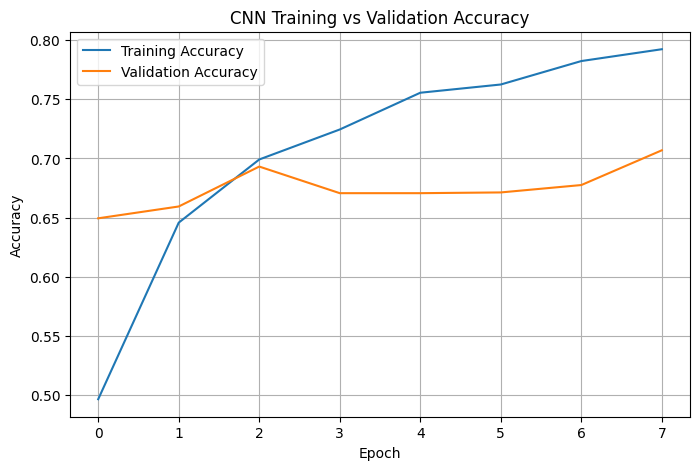

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')

plt.title('CNN Training vs Validation Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True)

plt.show()

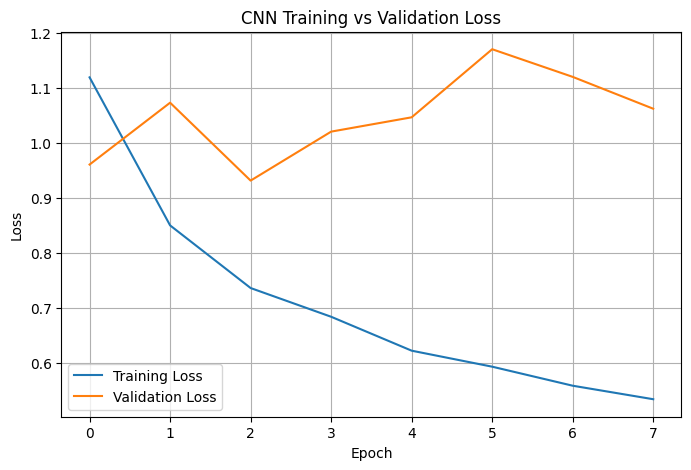

In [ ]:
plt.figure(figsize=(8, 5))

plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')

plt.title('CNN Training vs Validation Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)

plt.show()

In [ ]:
val_loss, val_accuracy = cnn_model.evaluate(val_ds, verbose=1)

print(f"\nValidation Loss: {val_loss:.4f}")
print(f"Validation Accuracy: {val_accuracy * 100:.2f}%")

50/50 ━━━━━━━━━━━━━━━━━━━━ 5s 95ms/step - accuracy: 0.6931 - loss: 0.9318

Validation Loss: 0.9318
Validation Accuracy: 69.31%


In [ ]:
import numpy as np

y_true = []
y_pred = []

for images, labels in val_ds:
    predictions = cnn_model.predict(images, verbose=0)

    predicted_classes = np.argmax(predictions, axis=1)

    y_true.extend(labels.numpy())
    y_pred.extend(predicted_classes)

y_true = np.array(y_true)
y_pred = np.array(y_pred)

print("Number of true labels:", len(y_true))
print("Number of predictions:", len(y_pred))

Number of true labels: 1600
Number of predictions: 1600


In [ ]:
from sklearn.metrics import classification_report

print(classification_report(
    y_true,
    y_pred,
    target_names=class_names,
    digits=4
))

              precision    recall  f1-score   support

      glioma     0.7019    0.5475    0.6152       400
  meningioma     0.6289    0.3050    0.4108       400
     notumor     0.6799    0.9875    0.8053       400
   pituitary     0.7271    0.9325    0.8171       400

    accuracy                         0.6931      1600
   macro avg     0.6844    0.6931    0.6621      1600
weighted avg     0.6844    0.6931    0.6621      1600



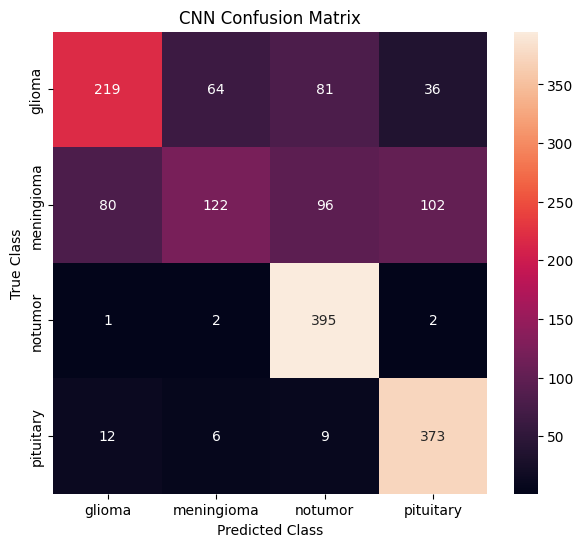

In [ ]:
from sklearn.metrics import confusion_matrix
import seaborn as sns

cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(7, 6))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    xticklabels=class_names,
    yticklabels=class_names
)

plt.xlabel("Predicted Class")
plt.ylabel("True Class")
plt.title("CNN Confusion Matrix")

plt.show()

Confusion Matrix:
[[219  64  81  36]
 [ 80 122  96 102]
 [  1   2 395   2]
 [ 12   6   9 373]]


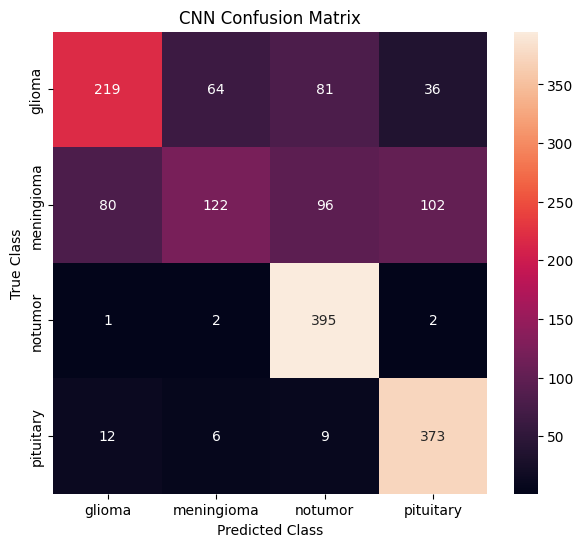

In [ ]:
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

cm = confusion_matrix(y_true, y_pred)

print("Confusion Matrix:")
print(cm)

plt.figure(figsize=(7, 6))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    xticklabels=class_names,
    yticklabels=class_names
)

plt.xlabel("Predicted Class")
plt.ylabel("True Class")
plt.title("CNN Confusion Matrix")

plt.show()

In [ ]:
import keras
import keras_hub

vit_model = keras_hub.models.ViTImageClassifier.from_preset(
    "vit_base_patch16_224_imagenet",
    num_classes=4
)

print("ViT loaded successfully!")

/usr/local/lib/python3.13/dist-packages/keras/src/layers/layer.py:431: UserWarning: `build()` was called on layer 'vi_t_image_classifier', however the layer does not have a `build()` method implemented and it looks like it has unbuilt state. This will cause the layer to be marked as built, despite not being actually built, which may cause failures down the line. Make sure to implement a proper `build()` method.
  warnings.warn(


ViT loaded successfully!


In [ ]:
vit_model.backbone.trainable = False

print("Backbone trainable:", vit_model.backbone.trainable)

Backbone trainable: False


In [ ]:
vit_model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-4),
    loss=keras.losses.SparseCategoricalCrossentropy(),
    metrics=["accuracy"]
)

print("ViT compiled successfully!")

ViT compiled successfully!


In [ ]:
vit_checkpoint = "/content/drive/MyDrive/Honours_MP/brain_tumor_vit_best.keras"

vit_early_stopping = keras.callbacks.EarlyStopping(
    monitor="val_accuracy",
    patience=2,
    mode="max",
    restore_best_weights=True,
    verbose=1
)

vit_checkpoint_callback = keras.callbacks.ModelCheckpoint(
    vit_checkpoint,
    monitor="val_accuracy",
    mode="max",
    save_best_only=True,
    verbose=1
)

vit_history = vit_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=5,
    callbacks=[
        vit_early_stopping,
        vit_checkpoint_callback
    ]
)

Epoch 1/5


/usr/local/lib/python3.13/dist-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


175/175 ━━━━━━━━━━━━━━━━━━━━ 0s 400ms/step - accuracy: 0.3554 - loss: 3.8857
Epoch 1: val_accuracy improved from None to 0.41125, saving model to /content/drive/MyDrive/Honours_MP/brain_tumor_vit_best.keras

Epoch 1: finished saving model to /content/drive/MyDrive/Honours_MP/brain_tumor_vit_best.keras
175/175 ━━━━━━━━━━━━━━━━━━━━ 117s 560ms/step - accuracy: 0.3554 - loss: 3.8857 - val_accuracy: 0.4112 - val_loss: 1.4841
Epoch 2/5
175/175 ━━━━━━━━━━━━━━━━━━━━ 0s 403ms/step - accuracy: 0.3829 - loss: 1.5956
Epoch 2: val_accuracy did not improve from 0.41125
175/175 ━━━━━━━━━━━━━━━━━━━━ 128s 522ms/step - accuracy: 0.3829 - loss: 1.5956 - val_accuracy: 0.4112 - val_loss: 1.3626
Epoch 3/5
175/175 ━━━━━━━━━━━━━━━━━━━━ 0s 398ms/step - accuracy: 0.4034 - loss: 1.4802
Epoch 3: val_accuracy improved from 0.41125 to 0.43375, saving model to /content/drive/MyDrive/Honours_MP/brain_tumor_vit_best.keras

Epoch 3: finished saving model to /content/drive/MyDrive/Honours_MP/brain_tumor_vit_best.keras
1

In [ ]:
vit_model.backbone.trainable = True

vit_model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-5),
    loss=keras.losses.SparseCategoricalCrossentropy(),
    metrics=["accuracy"]
)

print("Backbone trainable:", vit_model.backbone.trainable)

Backbone trainable: True


In [ ]:
vit_finetune_checkpoint = "/content/drive/MyDrive/Honours_MP/brain_tumor_vit_finetuned_best.keras"

vit_finetune_early_stopping = keras.callbacks.EarlyStopping(
    monitor="val_accuracy",
    patience=2,
    mode="max",
    restore_best_weights=True,
    verbose=1
)

vit_finetune_checkpoint_callback = keras.callbacks.ModelCheckpoint(
    vit_finetune_checkpoint,
    monitor="val_accuracy",
    mode="max",
    save_best_only=True,
    verbose=1
)

vit_finetune_history = vit_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=8,
    callbacks=[
        vit_finetune_early_stopping,
        vit_finetune_checkpoint_callback
    ]
)

Epoch 1/8


/usr/local/lib/python3.13/dist-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


175/175 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - accuracy: 0.5800 - loss: 1.0741
Epoch 1: val_accuracy improved from None to 0.41313, saving model to /content/drive/MyDrive/Honours_MP/brain_tumor_vit_finetuned_best.keras

Epoch 1: finished saving model to /content/drive/MyDrive/Honours_MP/brain_tumor_vit_finetuned_best.keras
175/175 ━━━━━━━━━━━━━━━━━━━━ 267s 1s/step - accuracy: 0.5800 - loss: 1.0741 - val_accuracy: 0.4131 - val_loss: 1.0377
Epoch 2/8
175/175 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - accuracy: 0.4345 - loss: 0.8013
Epoch 2: val_accuracy improved from 0.41313 to 0.59750, saving model to /content/drive/MyDrive/Honours_MP/brain_tumor_vit_finetuned_best.keras

Epoch 2: finished saving model to /content/drive/MyDrive/Honours_MP/brain_tumor_vit_finetuned_best.keras
175/175 ━━━━━━━━━━━━━━━━━━━━ 226s 1s/step - accuracy: 0.4345 - loss: 0.8013 - val_accuracy: 0.5975 - val_loss: 0.9316
Epoch 3/8
175/175 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - accuracy: 0.5018 - loss: 0.8553
Epoch 3: val_accuracy did n

In [ ]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

efficientnet_model = keras.applications.EfficientNetB0(
    include_top=False,
    weights="imagenet",
    input_shape=(224, 224, 3)
)

print("EfficientNetB0 loaded successfully!")

16705208/16705208 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step
EfficientNetB0 loaded successfully!


In [ ]:
efficientnet_model.trainable = False

print("Backbone trainable:", efficientnet_model.trainable)

Backbone trainable: False


In [ ]:
efficientnet_classifier = keras.Sequential([
    efficientnet_model,

    layers.GlobalAveragePooling2D(),

    layers.Dropout(0.3),

    layers.Dense(128, activation="relu"),

    layers.Dropout(0.2),

    layers.Dense(4, activation="softmax")
])

efficientnet_classifier.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ efficientnetb0 (Functional)     │ (None, 7, 7, 1280)     │     4,049,571 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_12 (Dropout)            │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       163,968 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_13 (Dropout)            │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 4)              │           516 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,214,055 (16.08 MB)

 Trainable params: 164,484 (642.52 KB)

 Non-trainable params: 4,049,571 (15.45 MB)

In [ ]:
efficientnet_classifier.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-4),
    loss=keras.losses.SparseCategoricalCrossentropy(),
    metrics=["accuracy"]
)

print("EfficientNetB0 classifier compiled successfully!")

EfficientNetB0 classifier compiled successfully!


In [ ]:
efficientnet_checkpoint = "/content/drive/MyDrive/Honours_MP/brain_tumor_efficientnet_best.keras"

efficientnet_early_stopping = keras.callbacks.EarlyStopping(
    monitor="val_accuracy",
    patience=2,
    mode="max",
    restore_best_weights=True,
    verbose=1
)

efficientnet_checkpoint_callback = keras.callbacks.ModelCheckpoint(
    efficientnet_checkpoint,
    monitor="val_accuracy",
    mode="max",
    save_best_only=True,
    verbose=1
)

efficientnet_history = efficientnet_classifier.fit(
    train_ds,
    validation_data=val_ds,
    epochs=5,
    callbacks=[
        efficientnet_early_stopping,
        efficientnet_checkpoint_callback
    ]
)

Epoch 1/5
175/175 ━━━━━━━━━━━━━━━━━━━━ 0s 79ms/step - accuracy: 0.6411 - loss: 0.9163
Epoch 1: val_accuracy improved from None to 0.77125, saving model to /content/drive/MyDrive/Honours_MP/brain_tumor_efficientnet_best.keras

Epoch 1: finished saving model to /content/drive/MyDrive/Honours_MP/brain_tumor_efficientnet_best.keras
175/175 ━━━━━━━━━━━━━━━━━━━━ 58s 147ms/step - accuracy: 0.6411 - loss: 0.9163 - val_accuracy: 0.7713 - val_loss: 0.6198
Epoch 2/5
175/175 ━━━━━━━━━━━━━━━━━━━━ 0s 81ms/step - accuracy: 0.7932 - loss: 0.5641
Epoch 2: val_accuracy improved from 0.77125 to 0.81125, saving model to /content/drive/MyDrive/Honours_MP/brain_tumor_efficientnet_best.keras

Epoch 2: finished saving model to /content/drive/MyDrive/Honours_MP/brain_tumor_efficientnet_best.keras
175/175 ━━━━━━━━━━━━━━━━━━━━ 20s 115ms/step - accuracy: 0.7932 - loss: 0.5641 - val_accuracy: 0.8112 - val_loss: 0.5280
Epoch 3/5
175/175 ━━━━━━━━━━━━━━━━━━━━ 0s 79ms/step - accuracy: 0.8261 - loss: 0.4643
Epoch 3: va

In [ ]:
from sklearn.metrics import classification_report, confusion_matrix
import numpy as np

# Get predictions
y_true = []
y_pred = []

for images, labels in val_ds:
    predictions = efficientnet_classifier.predict(images, verbose=0)

    y_true.extend(labels.numpy())
    y_pred.extend(np.argmax(predictions, axis=1))

y_true = np.array(y_true)
y_pred = np.array(y_pred)

# Retrieve class names from the dataset
class_names = val_ds.class_names

print("Classification Report:")
print(classification_report(
    y_true,
    y_pred,
    target_names=class_names
))

print("Confusion Matrix:")
cm = confusion_matrix(y_true, y_pred)
print(cm)

Classification Report:
              precision    recall  f1-score   support

      glioma       0.91      0.61      0.74       400
  meningioma       0.71      0.78      0.74       400
     notumor       0.86      0.99      0.92       400
   pituitary       0.88      0.95      0.91       400

    accuracy                           0.83      1600
   macro avg       0.84      0.83      0.83      1600
weighted avg       0.84      0.83      0.83      1600

Confusion Matrix:
[[246 107  32  15]
 [ 20 311  30  39]
 [  1   3 396   0]
 [  2  18   0 380]]


In [ ]:
!pip install -q gradio

In [ ]:
import gradio as gr
import numpy as np
from PIL import Image

CLASS_NAMES = ["Glioma", "Meningioma", "No Tumor", "Pituitary"]

def predict_brain_tumor(image):
    if image is None:
        return "Please upload an MRI image.", None

    # Convert image to RGB
    image = image.convert("RGB")

    # Resize to model input size
    image = image.resize((224, 224))

    # Convert to array
    img_array = np.array(image).astype("float32")

    # Add batch dimension
    img_array = np.expand_dims(img_array, axis=0)

    # Prediction
    predictions = efficientnet_classifier.predict(img_array, verbose=0)[0]

    predicted_index = np.argmax(predictions)
    predicted_class = CLASS_NAMES[predicted_index]
    confidence = float(predictions[predicted_index])

    # Create confidence dictionary for all classes
    confidence_scores = {
        CLASS_NAMES[i]: float(predictions[i])
        for i in range(len(CLASS_NAMES))
    }

    result = f"{predicted_class} ({confidence:.2%} confidence)"

    return result, confidence_scores

In [ ]:
import gradio as gr

custom_css = """
/* Main application */
.gradio-container {
    max-width: 1200px !important;
    margin: auto !important;
    padding: 25px 35px !important;
    font-family: Arial, sans-serif;
}

/* Header */
.app-header {
    text-align: center;
    padding: 10px 0 18px 0;
}

.app-title {
    font-size: 34px !important;
    font-weight: 700 !important;
    margin-bottom: 8px !important;
}

.app-subtitle {
    font-size: 16px !important;
    opacity: 0.8;
}

/* Cards */
.card {
    border-radius: 14px !important;
    padding: 20px !important;
}

/* Prediction output */
.prediction-box {
    border-radius: 12px !important;
}

/* Upload area */
.upload-box {
    min-height: 330px !important;
    border-radius: 14px !important;
}

/* Buttons */
button {
    border-radius: 10px !important;
    font-weight: 600 !important;
}

/* Submit button */
#submit-btn {
    font-size: 16px !important;
    min-height: 48px !important;
}

/* Clear button */
#clear-btn {
    font-size: 16px !important;
    min-height: 48px !important;
}

/* Information section */
.info-card {
    border-radius: 14px !important;
    padding: 18px 22px !important;
    margin-top: 18px !important;
}

/* Disclaimer */
.disclaimer {
    font-size: 13px !important;
    opacity: 0.75;
    line-height: 1.6;
}

/* Model badge */
.model-badge {
    text-align: center;
    font-size: 13px;
    margin-top: 12px;
    opacity: 0.8;
}
"""

with gr.Blocks(
    title="Brain Tumor Detection using MRI",
    css=custom_css,
    theme=gr.themes.Soft(
        primary_hue="blue",
        secondary_hue="slate",
        neutral_hue="slate"
    )
) as demo:

    # =========================
    # HEADER
    # =========================

    gr.HTML("""
        <div class="app-header">
            <div class="app-title">
                🧠 Brain Tumor Detection using MRI
            </div>

            <div class="app-subtitle">
                AI-assisted classification of brain MRI images
            </div>

            <div class="model-badge">
                ⚙️ Powered by EfficientNetB0 &nbsp;•&nbsp;
                4-Class Classification
            </div>
        </div>
    """)

    # =========================
    # MAIN APPLICATION
    # =========================

    with gr.Row():

        # LEFT SIDE — IMAGE
        with gr.Column(scale=1):

            gr.Markdown("### 📤 Upload MRI Scan")

            image_input = gr.Image(
                type="pil",
                label="Brain MRI Image",
                elem_classes="upload-box"
            )

        # RIGHT SIDE — RESULTS
        with gr.Column(scale=1):

            gr.Markdown("### 🔍 AI Analysis")

            prediction_output = gr.Textbox(
                label="Prediction",
                placeholder="Prediction will appear here...",
                interactive=False,
                elem_classes="prediction-box"
            )

            confidence_output = gr.Label(
                label="Class Confidence",
                num_top_classes=4
            )

    # =========================
    # BUTTONS
    # =========================

    with gr.Row():

        clear_btn = gr.Button(
            "Clear",
            variant="secondary",
            elem_id="clear-btn"
        )

        submit_btn = gr.Button(
            "🔎 Analyze MRI",
            variant="primary",
            elem_id="submit-btn"
        )

    # =========================
    # INFORMATION
    # =========================

    gr.HTML("""
        <div class="info-card">

            <h3>🧬 Supported Classifications</h3>

            <p>
                The model classifies MRI images into four categories:
            </p>

            <ul>
                <li><b>Glioma</b></li>
                <li><b>Meningioma</b></li>
                <li><b>Pituitary Tumor</b></li>
                <li><b>No Tumor</b></li>
            </ul>

            <p>
                <b>Model:</b> EfficientNetB0 &nbsp; | &nbsp;
                <b>Validation Accuracy:</b> 83.31%
            </p>

        </div>
    """)

    gr.HTML("""
        <div class="info-card disclaimer">

            <b>⚠️ Important Disclaimer</b>

            <p>
                This application is an academic healthcare AI prototype
                developed for educational and research purposes.
                It is not intended to provide medical diagnosis or
                replace assessment by a qualified healthcare professional.
            </p>

        </div>
    """)

    # =========================
    # BUTTON ACTIONS
    # =========================

    submit_btn.click(
        fn=predict_brain_tumor,
        inputs=image_input,
        outputs=[
            prediction_output,
            confidence_output
        ]
    )

    clear_btn.click(
        fn=lambda: (None, "", None),
        inputs=None,
        outputs=[
            image_input,
            prediction_output,
            confidence_output
        ]
    )


demo.launch(share=True)

/tmp/ipykernel_4697/236471744.py:87: UserWarning: The parameters have been moved from the Blocks constructor to the launch() method in Gradio 6.0: theme, css. Please pass these parameters to launch() instead.
  with gr.Blocks(


Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://ef2e8deef42ee41844.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)
